<a href="https://colab.research.google.com/github/ikhsanti/Probabilitas-dan-Statistika/blob/main/Probabilitas_Distribusi_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Probabilitas dan Distribusi Probabilitas dengan Python
**Studi eksplorasi library, implementasi, dan studi kasus Teknik Informatika**

Isi notebook:
1. Eksplorasi library Python untuk probabilitas
2. Probabilitas dasar (ruang sampel, kombinatorika)
3. Probabilitas bersyarat dan teorema Bayes
4. Kombinasi kejadian (gabungan, irisan, independensi, keandalan sistem)
5. Simulasi Monte Carlo
6. Distribusi probabilitas diskrit
7. Distribusi probabilitas kontinu
8. Studi kasus lanjutan (Naive Bayes, antrian M/M/1, rantai Markov)
9. Rekapitulasi perbandingan teori vs Python
10. Kesimpulan

**Catatan metodologi.** Contoh soal dirancang dengan bantuan AI. Setiap soal diperiksa dengan tiga cara: (a) rumus matematis yang diturunkan manual, (b) perhitungan eksak dengan Python (`fractions`, `scipy.stats`, `sympy`), dan (c) simulasi acak. Jika (a), (b), dan (c) sepakat, konsep soal dianggap benar. Semua hasil dicatat di tabel rekapitulasi (bagian 9). Seed acak dibuat tetap supaya hasil dapat direproduksi.

## 1. Eksplorasi Library Python

| Library | Kegunaan | Fungsi/objek utama | Contoh singkat |
|---|---|---|---|
| `math` | Kombinatorika dan fungsi matematika dasar | `comb`, `perm`, `factorial`, `exp`, `gamma` | `math.comb(52, 5)` |
| `itertools` | Membangkitkan ruang sampel dan kombinasi | `product`, `permutations`, `combinations` | `product(range(1,7), repeat=2)` |
| `fractions` | Probabilitas eksak sebagai pecahan | `Fraction` | `Fraction(6, 36)` menjadi `1/6` |
| `random` | Pengacakan bawaan Python | `seed`, `random`, `choice`, `sample`, `randrange` | `random.choice(["H","T"])` |
| `statistics` | Statistika deskriptif dasar | `mean`, `variance`, `stdev`, `mode` | `statistics.mean(data)` |
| `numpy` | Simulasi cepat (vektor) dan array | `random.default_rng`, `binomial`, `poisson`, `exponential`, `choice` | `rng.binomial(10, .5, 1000)` |
| `scipy.stats` | Distribusi probabilitas lengkap | `pmf`, `pdf`, `cdf`, `sf`, `ppf`, `rvs`, `mean`, `var`, `interval`, `expect` | `stats.norm.cdf(1.96)` |
| `sympy` / `sympy.stats` | Aljabar simbolik, turunan rumus, probabilitas simbolik | `symbols`, `integrate`, `Rational`, `Die`, `P`, `E`, `variance` | `sp.integrate(sp.exp(-x), (x,0,sp.oo))` |
| `pandas` | Tabel data, frekuensi, rekapitulasi | `DataFrame`, `value_counts`, `crosstab` | `s.value_counts(normalize=True)` |
| `matplotlib` | Visualisasi dasar | `plot`, `bar`, `hist`, `subplots` | `plt.hist(x, density=True)` |
| `seaborn` | Visualisasi statistik | `histplot`, `kdeplot`, `set_theme` | `sns.histplot(x, kde=True)` |

Library lanjutan yang relevan (hanya disebutkan, tidak dijalankan di notebook ini): `statsmodels` (uji hipotesis, model regresi), `scikit-learn` (`MultinomialNB`, `GaussianNB` untuk klasifikasi probabilistik), `PyMC` (inferensi Bayesian dengan MCMC), dan `pgmpy` (jaringan Bayesian).

In [1]:
import math, itertools, random, statistics
from fractions import Fraction
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, integrate
import sympy as sp

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(2026)
random.seed(2026)

# Pencatat hasil untuk tabel rekapitulasi (bagian 9)
hasil = []
def catat(bagian, kasus, teori, simulasi):
    hasil.append({"Bagian": bagian, "Kasus": kasus, "Teori/Eksak": float(teori),
                  "Simulasi": float(simulasi), "Selisih mutlak": abs(float(teori) - float(simulasi))})
print("Setup selesai.")

Setup selesai.


### 1.1 Demonstrasi fungsi dasar tiap library

In [2]:
# math
print("math  :", math.comb(52, 5), "kombinasi 5 kartu | P(5,2) =", math.perm(5, 2), "| 5! =", math.factorial(5))

# itertools + fractions
S = list(itertools.product(range(1, 7), repeat=2))
print("itertools: ruang sampel 2 dadu =", len(S), "titik; kombinasi 2 dari ABCD =", list(itertools.combinations("ABCD", 2)))
print("fractions: P(jumlah=7) =", Fraction(sum(a + b == 7 for a, b in S), len(S)))

# random dan numpy
print("random:", random.choice(["Kepala", "Ekor"]), "| numpy binomial(10,.5) x5 =", rng.binomial(10, .5, 5))

# statistics
data = [2, 3, 3, 5, 7]
print("statistics: mean =", statistics.mean(data), "| var sampel =", statistics.variance(data), "| modus =", statistics.mode(data))

# scipy.stats: satu objek distribusi, banyak metode
d = stats.norm(loc=0, scale=1)
print("scipy.stats Normal(0,1): pdf(0) = %.4f, cdf(1.96) = %.4f, sf(1.96) = %.4f, ppf(0.975) = %.4f" %
      (d.pdf(0), d.cdf(1.96), d.sf(1.96), d.ppf(0.975)))
print("   mean, var =", d.mean(), d.var(), "| interval 95% =", tuple(round(float(v), 3) for v in d.interval(0.95)), "| rvs(3) =", d.rvs(3, random_state=1).round(3))
print("   E[X^2] lewat expect =", round(d.expect(lambda x: x**2), 4))

# sympy (simbolik) dan sympy.stats
x = sp.symbols("x", positive=True)
print("sympy: integral e^-x dari 0..inf =", sp.integrate(sp.exp(-x), (x, 0, sp.oo)))
from sympy.stats import Die, Binomial, P, E, variance
D1, D2 = Die("D1", 6), Die("D2", 6)
Xb = Binomial("Xb", 10, sp.Rational(1, 2))
print("sympy.stats: P(D1+D2=7) =", P(sp.Eq(D1 + D2, 7)), "| E[D1+D2] =", E(D1 + D2), "| E,Var Binomial(10,1/2) =", E(Xb), variance(Xb))

# pandas
print(pd.Series(rng.integers(1, 7, 6000)).value_counts(normalize=True).sort_index().round(3).to_string())

math  : 2598960 kombinasi 5 kartu | P(5,2) = 20 | 5! = 120
itertools: ruang sampel 2 dadu = 36 titik; kombinasi 2 dari ABCD = [('A', 'B'), ('A', 'C'), ('A', 'D'), ('B', 'C'), ('B', 'D'), ('C', 'D')]
fractions: P(jumlah=7) = 1/6
random: Kepala | numpy binomial(10,.5) x5 = [4 6 5 4 4]
statistics: mean = 4 | var sampel = 4 | modus = 3
scipy.stats Normal(0,1): pdf(0) = 0.3989, cdf(1.96) = 0.9750, sf(1.96) = 0.0250, ppf(0.975) = 1.9600
   mean, var = 0.0 1.0 | interval 95% = (-1.96, 1.96) | rvs(3) = [ 1.624 -0.612 -0.528]
   E[X^2] lewat expect = 1.0
sympy: integral e^-x dari 0..inf = 1
sympy.stats: P(D1+D2=7) = 1/6 | E[D1+D2] = 7 | E,Var Binomial(10,1/2) = 5 5/2
1    0.166
2    0.170
3    0.170
4    0.164
5    0.163
6    0.167


Ringkasan metode objek distribusi `scipy.stats` yang dipakai di seluruh notebook:

| Metode | Arti | Notasi |
|---|---|---|
| `pmf(k)` / `pdf(x)` | massa (diskrit) / kepadatan (kontinu) | $P(X=k)$ / $f(x)$ |
| `cdf(x)` | probabilitas kumulatif | $P(X\le x)$ |
| `sf(x)` | survival function | $P(X>x)=1-F(x)$ |
| `ppf(q)` | kuantil (invers cdf) | $F^{-1}(q)$ |
| `rvs(size)` | pembangkit sampel acak | simulasi |
| `mean()`, `var()`, `std()` | nilai harapan, varians, simpangan baku | $E[X]$, $\mathrm{Var}(X)$ |

## 2. Probabilitas Dasar

### 2.1 Dua dadu (ruang sampel, kejadian)
**Soal.** Dua dadu dilempar. Hitung (a) $P(\text{jumlah}=7)$, (b) $P(\text{jumlah}\ge 10)$, (c) $P(\text{minimal satu angka 6 dalam 4 lemparan satu dadu})$ (masalah Chevalier de Méré).

**Jawaban matematis:** (a) $6/36=1/6$; (b) $(4+3+... )$ yaitu jumlah 10, 11, 12 memiliki $3+2+1=6$ titik, sehingga $6/36=1/6$; (c) $1-(5/6)^4\approx 0{,}5177$.

In [3]:
S = list(itertools.product(range(1, 7), repeat=2))
p_a = Fraction(sum(a + b == 7 for a, b in S), len(S))
p_b = Fraction(sum(a + b >= 10 for a, b in S), len(S))
p_c = 1 - Fraction(5, 6) ** 4
print("Eksak (a) =", p_a, "| (b) =", p_b, "| (c) =", p_c, "=", float(p_c))

N = 1_000_000
d1, d2 = rng.integers(1, 7, N), rng.integers(1, 7, N)
sim_a, sim_b = ((d1 + d2) == 7).mean(), ((d1 + d2) >= 10).mean()
sim_c = (rng.integers(1, 7, (N, 4)) == 6).any(axis=1).mean()
print("Simulasi (a) = %.4f | (b) = %.4f | (c) = %.4f" % (sim_a, sim_b, sim_c))
catat("2 Dasar", "P(jumlah dua dadu = 7)", p_a, sim_a)
catat("2 Dasar", "P(jumlah dua dadu >= 10)", p_b, sim_b)
catat("2 Dasar", "P(minimal satu 6 dalam 4 lemparan)", p_c, sim_c)

Eksak (a) = 1/6 | (b) = 1/6 | (c) = 671/1296 = 0.5177469135802469
Simulasi (a) = 0.1669 | (b) = 0.1665 | (c) = 0.5170


### 2.2 Kombinatorika: *full house* pada 5 kartu poker
**Soal.** Dari 52 kartu diambil 5 kartu. Berapa peluang *full house* (tiga kartu seperingkat + dua kartu seperingkat lain)?

**Jawaban matematis:** $\dfrac{13\binom{4}{3}\cdot 12\binom{4}{2}}{\binom{52}{5}}=\dfrac{3744}{2.598.960}\approx 0{,}001441$.

In [4]:
eksak = 13 * math.comb(4, 3) * 12 * math.comb(4, 2) / math.comb(52, 5)
print("Eksak:", eksak, "=", 13 * math.comb(4, 3) * 12 * math.comb(4, 2), "/", math.comb(52, 5))

hit, total = 0, 0
onehot = np.eye(13, dtype=np.int8)
for _ in range(10):                          # 10 batch x 200.000 tangan = 2 juta tangan
    n = 200_000
    kartu = rng.random((n, 52)).argsort(axis=1)[:, :5]   # 5 kartu acak tanpa pengembalian
    cnt = onehot[kartu % 13].sum(axis=1)                  # banyak kartu per peringkat
    hit += ((cnt == 3).any(axis=1) & (cnt == 2).any(axis=1)).sum()
    total += n
print("Simulasi:", hit / total)
catat("2 Dasar", "P(full house)", eksak, hit / total)

Eksak: 0.0014405762304921968 = 3744 / 2598960
Simulasi: 0.001444


### 2.3 *Birthday paradox* dan tabrakan hash
**Soal.** (a) Dalam kelas 23 orang, berapa peluang ada dua orang berulang tahun sama? (b) Sebuah fungsi hash 32-bit menghasilkan $N=2^{32}$ nilai. Berapa banyak data agar peluang tabrakan (*collision*) mencapai 50%?

**Rumus:** $P(\text{tabrakan})=1-\prod_{i=0}^{n-1}\left(1-\tfrac{i}{N}\right)\approx 1-e^{-n^2/(2N)}$, sehingga $n_{50\%}\approx\sqrt{2N\ln 2}$.

In [5]:
def p_tabrakan(n, N):
    return 1 - math.exp(sum(math.log1p(-i / N) for i in range(n)))

eksak = p_tabrakan(23, 365)
a = rng.integers(0, 365, (200_000, 23)); a.sort(axis=1)
sim = (a[:, 1:] == a[:, :-1]).any(axis=1).mean()
print("(a) n=23: eksak = %.4f | simulasi = %.4f" % (eksak, sim))
catat("2 Dasar", "Birthday paradox n=23", eksak, sim)

N = 2 ** 32
n50 = math.ceil(math.sqrt(2 * N * math.log(2)))
print("(b) estimasi n untuk 50%% tabrakan pada hash 32-bit: %d data" % n50)
print("    peluang eksak pada n tersebut = %.4f" % p_tabrakan(n50, N))
print("    bandingkan: ruang nilai = %.2e, tetapi tabrakan sudah wajar pada ~%.1e data" % (N, n50))

(a) n=23: eksak = 0.5073 | simulasi = 0.5044
(b) estimasi n untuk 50% tabrakan pada hash 32-bit: 77163 data
    peluang eksak pada n tersebut = 0.5000
    bandingkan: ruang nilai = 4.29e+09, tetapi tabrakan sudah wajar pada ~7.7e+04 data


**Interpretasi.** Peluang tabrakan tumbuh kira-kira kuadratik terhadap jumlah data, bukan linear. Hash 32-bit (4,29 miliar nilai) sudah mencapai 50% peluang tabrakan di sekitar 77 ribu data. Karena itu hash 32-bit tidak cocok sebagai pengenal unik untuk data besar.

## 3. Probabilitas Bersyarat dan Teorema Bayes

$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad P(A\mid B)=\frac{P(B\mid A)P(A)}{P(B)},\qquad P(B)=\sum_i P(B\mid A_i)P(A_i)$$

### 3.1 Filter spam
**Soal.** 40% email adalah spam. Kata "gratis" muncul di 60% spam dan 5% email non-spam (*ham*). Jika sebuah email berisi kata "gratis", berapa peluang email itu spam?

**Jawaban matematis:** $P(S\mid G)=\dfrac{0{,}6\cdot0{,}4}{0{,}6\cdot0{,}4+0{,}05\cdot0{,}6}=\dfrac{0{,}24}{0{,}27}\approx0{,}8889$.

In [6]:
p_s, p_g_s, p_g_h = 0.40, 0.60, 0.05
p_g = p_g_s * p_s + p_g_h * (1 - p_s)
post = p_g_s * p_s / p_g
print("P(kata 'gratis') = %.3f | P(spam | gratis) = %.4f" % (p_g, post))

n = 2_000_000
spam = rng.random(n) < p_s
ada = np.where(spam, rng.random(n) < p_g_s, rng.random(n) < p_g_h)
sim = spam[ada].mean()
print("Simulasi P(spam | gratis) = %.4f" % sim)
catat("3 Bayes", "Spam: P(spam | kata 'gratis')", post, sim)

P(kata 'gratis') = 0.270 | P(spam | gratis) = 0.8889
Simulasi P(spam | gratis) = 0.8894


### 3.2 Deteksi malware dan kekeliruan *base rate*
**Soal.** Antivirus memiliki sensitivitas 99% (mendeteksi file berbahaya) dan *false positive rate* 5%. Hanya 1% file di sebuah server yang benar-benar berbahaya. Jika sebuah file ditandai berbahaya, berapa peluang file itu benar-benar berbahaya?

**Jawaban matematis:** $\dfrac{0{,}99\cdot0{,}01}{0{,}99\cdot0{,}01+0{,}05\cdot0{,}99}=\dfrac{0{,}0099}{0{,}0594}=\dfrac16\approx0{,}1667$. Kita turunkan rumus simbolik dengan `sympy`.

Rumus simbolik: prevalensi*sensitivitas/(fpr*(1 - prevalensi) + prevalensi*sensitivitas)
Nilai eksak: 1/6 = 0.16666666666666666
Simulasi P(berbahaya | alarm) = 0.1674


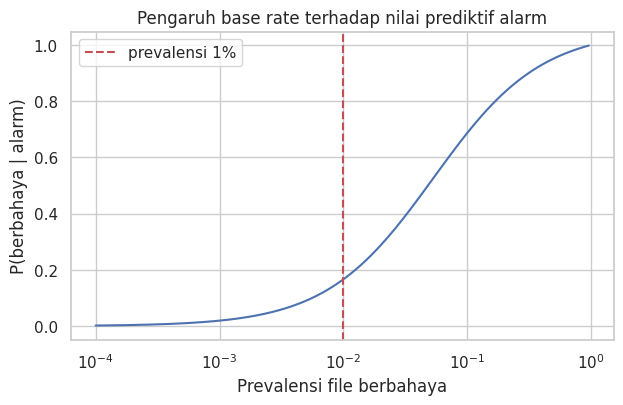

In [7]:
Pv, se, fp = sp.symbols("prevalensi sensitivitas fpr", positive=True)
posterior = se * Pv / (se * Pv + fp * (1 - Pv))
print("Rumus simbolik:", posterior)
eksak = posterior.subs({Pv: sp.Rational(1, 100), se: sp.Rational(99, 100), fp: sp.Rational(5, 100)})
print("Nilai eksak:", eksak, "=", float(eksak))

n = 3_000_000
bahaya = rng.random(n) < 0.01
alarm = np.where(bahaya, rng.random(n) < 0.99, rng.random(n) < 0.05)
sim = bahaya[alarm].mean()
print("Simulasi P(berbahaya | alarm) = %.4f" % sim)
catat("3 Bayes", "Malware: P(berbahaya | alarm)", float(eksak), sim)

prev = np.logspace(-4, 0, 200, endpoint=False)
ppv = 0.99 * prev / (0.99 * prev + 0.05 * (1 - prev))
plt.figure(figsize=(7, 4)); plt.semilogx(prev, ppv)
plt.axvline(0.01, color="r", ls="--", label="prevalensi 1%")
plt.xlabel("Prevalensi file berbahaya"); plt.ylabel("P(berbahaya | alarm)")
plt.title("Pengaruh base rate terhadap nilai prediktif alarm"); plt.legend(); plt.show()

**Interpretasi.** Walau antivirus tampak akurat (99%), hanya sekitar 1 dari 6 alarm yang benar. Penyebabnya adalah file berbahaya sangat jarang, sehingga jumlah alarm palsu dari file normal mendominasi. Pelajaran: kualitas detektor tidak dapat dinilai tanpa memperhitungkan *base rate*.

### 3.3 Monty Hall
**Soal.** Ada 3 pintu, satu berisi mobil. Anda memilih satu pintu, pembawa acara membuka pintu lain yang kosong, lalu menawarkan ganti pilihan. Mana lebih baik: tetap atau ganti?

**Jawaban matematis:** tetap menang dengan peluang $1/3$, ganti menang dengan peluang $2/3$ (menang bila pilihan awal salah).

In [8]:
def monty(ganti, n=100_000):
    menang = 0
    for _ in range(n):
        mobil, pilih = random.randrange(3), random.randrange(3)
        buka = random.choice([d for d in range(3) if d != pilih and d != mobil])
        if ganti:
            pilih = next(d for d in range(3) if d != pilih and d != buka)
        menang += (pilih == mobil)
    return menang / n

tetap, ganti = monty(False), monty(True)
print("Simulasi: tetap = %.4f | ganti = %.4f" % (tetap, ganti))
catat("3 Bayes", "Monty Hall: strategi ganti", 2/3, ganti)
catat("3 Bayes", "Monty Hall: strategi tetap", 1/3, tetap)

Simulasi: tetap = 0.3320 | ganti = 0.6668


### 3.4 Peluang total: *load balancer*
**Soal.** Load balancer membagi trafik ke server A, B, C dengan proporsi 50%, 30%, 20%. Tingkat error masing-masing 1%, 2%, 5%. (a) Berapa peluang sebuah request error? (b) Jika sebuah request error, berapa peluang ia diproses server C?

**Jawaban matematis:** (a) $0{,}5(0{,}01)+0{,}3(0{,}02)+0{,}2(0{,}05)=0{,}021$; (b) $\dfrac{0{,}2\cdot0{,}05}{0{,}021}=\dfrac{0{,}010}{0{,}021}\approx0{,}4762$.

In [9]:
prior = np.array([0.5, 0.3, 0.2]); err = np.array([0.01, 0.02, 0.05])
p_err = (prior * err).sum()
post = prior * err / p_err
print("P(error) = %.4f | P(server | error) = %s" % (p_err, post.round(4)))

n = 4_000_000
srv = rng.choice(3, size=n, p=prior)
e = rng.random(n) < err[srv]
print("Simulasi P(error) = %.4f | P(C | error) = %.4f" % (e.mean(), (srv[e] == 2).mean()))
catat("3 Bayes", "Load balancer: P(error)", p_err, e.mean())
catat("3 Bayes", "Load balancer: P(server C | error)", post[2], (srv[e] == 2).mean())

pd.DataFrame({"Proporsi trafik (prior)": prior, "Tingkat error": err, "P(server | error) (posterior)": post},
             index=["A", "B", "C"]).round(4)

P(error) = 0.0210 | P(server | error) = [0.2381 0.2857 0.4762]
Simulasi P(error) = 0.0210 | P(C | error) = 0.4780


,Proporsi trafik (prior),Tingkat error,P(server | error) (posterior)
A,0.5,0.01,0.2381
B,0.3,0.02,0.2857
C,0.2,0.05,0.4762


**Interpretasi.** Server C hanya menangani 20% trafik, tetapi menyumbang sekitar 47,6% dari seluruh error. Teorema Bayes dipakai di sini untuk menelusuri sumber masalah (*root cause*) dari gejala yang teramati.

## 4. Kombinasi Kejadian

### 4.1 Gabungan, irisan, dan independensi
$P(A\cup B)=P(A)+P(B)-P(A\cap B)$. Dua kejadian independen jika $P(A\cap B)=P(A)P(B)$.

**Soal.** Dua dadu dilempar. $A$: dadu pertama genap. $B$: jumlah kedua dadu 7. $C$: jumlah kedua dadu 8. Periksa apakah $A$ independen terhadap $B$, dan terhadap $C$.

In [10]:
S = list(itertools.product(range(1, 7), repeat=2))
def P_(f): return Fraction(sum(1 for s in S if f(s)), len(S))
A = lambda s: s[0] % 2 == 0
B = lambda s: s[0] + s[1] == 7
C = lambda s: s[0] + s[1] == 8

for nama, K in [("B (jumlah 7)", B), ("C (jumlah 8)", C)]:
    pa, pk, pak = P_(A), P_(K), P_(lambda s: A(s) and K(s))
    punion = P_(lambda s: A(s) or K(s))
    print(f"A & {nama}: P(A)={pa}, P(K)={pk}, P(A∩K)={pak}, P(A)P(K)={pa*pk} -> independen? {pak == pa*pk}")
    print(f"    P(A∪K) = {punion}  (cek rumus: {pa + pk - pak})")

A & B (jumlah 7): P(A)=1/2, P(K)=1/6, P(A∩K)=1/12, P(A)P(K)=1/12 -> independen? True
    P(A∪K) = 7/12  (cek rumus: 7/12)
A & C (jumlah 8): P(A)=1/2, P(K)=5/36, P(A∩K)=1/12, P(A)P(K)=5/72 -> independen? False
    P(A∪K) = 5/9  (cek rumus: 5/9)


**Interpretasi.** Jumlah 7 selalu bisa dicapai dari setiap hasil dadu pertama, sehingga mengetahui dadu pertama genap tidak mengubah peluang jumlah 7 (independen). Jumlah 8 tidak demikian: dadu pertama = 1 membuatnya mustahil, sehingga $A$ dan $C$ tidak independen.

### 4.2 Inklusi-eksklusi: kekuatan kata sandi
**Soal.** Kata sandi 8 karakter dipilih acak dari 62 karakter (a-z, A-Z, 0-9). Berapa peluang kata sandi memuat minimal satu huruf kecil, satu huruf besar, dan satu angka?

**Jawaban matematis (inklusi-eksklusi):** hitung yang gagal memuat salah satu jenis, lalu kurangkan:
$$\frac{62^8-\left(52^8+2\cdot36^8\right)+\left(2\cdot26^8+10^8\right)}{62^8}$$

In [11]:
total = 62 ** 8
bagus = total - (52**8 + 2 * 36**8) + (2 * 26**8 + 10**8)
eksak = bagus / total
print("Eksak = %.6f" % eksak)

n = 2_000_000
pw = rng.integers(0, 62, (n, 8))            # 0-9 angka, 10-35 besar, 36-61 kecil
ok = ((pw < 10).any(1)) & ((pw >= 10) & (pw < 36)).any(1) & (pw >= 36).any(1)
print("Simulasi = %.6f" % ok.mean())
catat("4 Kombinasi", "Password 8 char memuat 3 jenis karakter", eksak, ok.mean())

Eksak = 0.731226
Simulasi = 0.730986


### 4.3 Keandalan sistem (seri dan paralel)
**Soal.** Sistem web terdiri dari *load balancer* (andal 0,999), lalu dua *app server* identik yang bekerja paralel (masing-masing andal 0,95; sistem hidup bila minimal satu hidup), lalu database (andal 0,99). Komponen gagal secara independen. Berapa keandalan sistem?

**Jawaban matematis:** $R=0{,}999\times\left[1-(1-0{,}95)^2\right]\times0{,}99=0{,}999\times0{,}9975\times0{,}99\approx0{,}98655$.

In [12]:
eksak = 0.999 * (1 - (1 - 0.95) ** 2) * 0.99
n = 3_000_000
lb = rng.random(n) < 0.999
a1, a2 = rng.random(n) < 0.95, rng.random(n) < 0.95
db = rng.random(n) < 0.99
sim = (lb & (a1 | a2) & db).mean()
print("Eksak = %.5f | Simulasi = %.5f" % (eksak, sim))
print("Tanpa replikasi (1 app server): %.5f -> replikasi menaikkan keandalan %.2f poin persentase" %
      (0.999 * 0.95 * 0.99, 100 * (eksak - 0.999 * 0.95 * 0.99)))
catat("4 Kombinasi", "Keandalan sistem seri-paralel", eksak, sim)

Eksak = 0.98654 | Simulasi = 0.98647
Tanpa replikasi (1 app server): 0.93956 -> replikasi menaikkan keandalan 4.70 poin persentase


## 5. Simulasi Percobaan Acak (Monte Carlo)

### 5.1 Hukum bilangan besar dan estimasi $\pi$
Titik acak $(x,y)$ pada persegi satuan jatuh di seperempat lingkaran dengan peluang $\pi/4$. Jadi $\pi\approx4\times$ (proporsi titik di dalam lingkaran). Galat Monte Carlo menyusut sebanding $1/\sqrt{n}$.

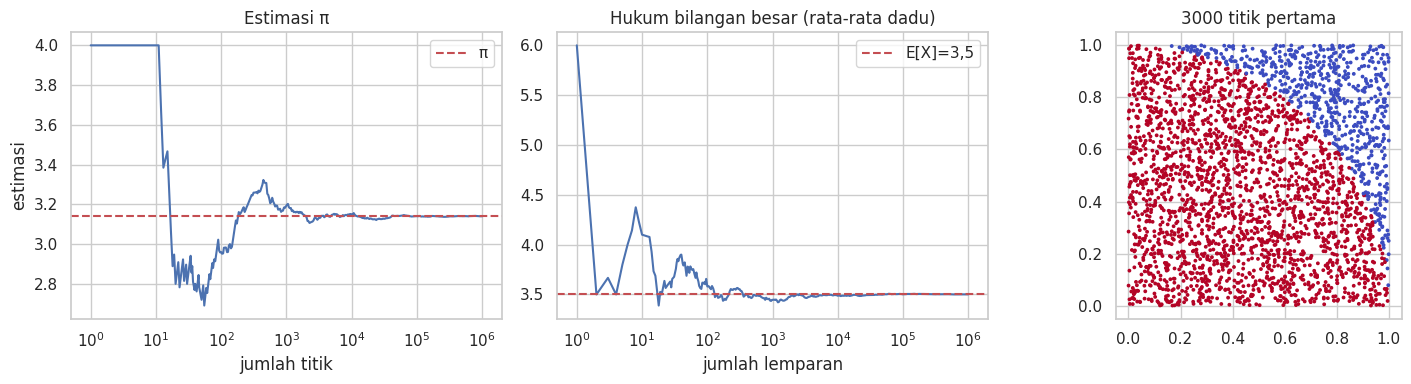

π estimasi = 3.14013 | π sebenarnya = 3.14159 | galat = 0.00146 | galat teoretis ~ 0.00164


In [13]:
N = 1_000_000
x, y = rng.random(N), rng.random(N)
dalam = (x**2 + y**2) <= 1
k = np.arange(1, N + 1)
pi_kum = 4 * np.cumsum(dalam) / k
rata_dadu = np.cumsum(rng.integers(1, 7, N)) / k

idx = np.unique(np.logspace(0, 6, 400).astype(int)) - 1
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].semilogx(idx + 1, pi_kum[idx]); ax[0].axhline(math.pi, color="r", ls="--", label="π")
ax[0].set(title="Estimasi π", xlabel="jumlah titik", ylabel="estimasi"); ax[0].legend()
ax[1].semilogx(idx + 1, rata_dadu[idx]); ax[1].axhline(3.5, color="r", ls="--", label="E[X]=3,5")
ax[1].set(title="Hukum bilangan besar (rata-rata dadu)", xlabel="jumlah lemparan"); ax[1].legend()
ax[2].scatter(x[:3000], y[:3000], c=dalam[:3000], cmap="coolwarm", s=3); ax[2].set_aspect("equal"); ax[2].set_title("3000 titik pertama")
plt.tight_layout(); plt.show()

print("π estimasi = %.5f | π sebenarnya = %.5f | galat = %.5f | galat teoretis ~ %.5f" %
      (pi_kum[-1], math.pi, abs(pi_kum[-1] - math.pi), 4 * math.sqrt((math.pi/4) * (1 - math.pi/4) / N)))
catat("5 Monte Carlo", "Estimasi pi (1 juta titik)", math.pi, pi_kum[-1])

## 6. Distribusi Probabilitas Diskrit

Untuk tiap distribusi kita hitung: probabilitas ($P(X=k)$, $P(X\le k)$, $P(X>k)$), nilai harapan, varians, lalu kita bandingkan dengan simulasi.

### 6.1 Binomial: pengiriman paket
**Soal.** Sebuah node mengirim $n=20$ paket. Tiap paket hilang dengan peluang $p=0{,}10$ secara independen. $X$ = jumlah paket hilang. Hitung $P(X=0)$, $P(X\le2)$, $P(X\ge5)$, $E[X]$, $\mathrm{Var}(X)$.

**Rumus:** $P(X=k)=\binom{n}{k}p^k(1-p)^{n-k}$, $E[X]=np=2$, $\mathrm{Var}(X)=np(1-p)=1{,}8$.

In [14]:
n, p = 20, 0.10
X = stats.binom(n, p)
p0, p_le2, p_ge5 = X.pmf(0), X.cdf(2), X.sf(4)
print("P(X=0) = %.4f (cek manual 0.9^20 = %.4f)" % (p0, 0.9 ** 20))
print("P(X<=2) = %.4f | P(X>=5) = %.4f" % (p_le2, p_ge5))
print("E[X] = %.2f (np) | Var = %.2f (np(1-p))" % (X.mean(), X.var()))
print("E[X] manual = sum k*pmf(k) = %.4f" % sum(k * X.pmf(k) for k in range(n + 1)))

s = rng.binomial(n, p, 2_000_000)
print("Simulasi: P(0)=%.4f P(<=2)=%.4f P(>=5)=%.4f mean=%.3f var=%.3f" % ((s == 0).mean(), (s <= 2).mean(), (s >= 5).mean(), s.mean(), s.var()))
catat("6 Diskrit", "Binomial(20,0.1): P(X=0)", p0, (s == 0).mean())
catat("6 Diskrit", "Binomial(20,0.1): P(X<=2)", p_le2, (s <= 2).mean())
catat("6 Diskrit", "Binomial(20,0.1): P(X>=5)", p_ge5, (s >= 5).mean())

P(X=0) = 0.1216 (cek manual 0.9^20 = 0.1216)
P(X<=2) = 0.6769 | P(X>=5) = 0.0432
E[X] = 2.00 (np) | Var = 1.80 (np(1-p))
E[X] manual = sum k*pmf(k) = 2.0000
Simulasi: P(0)=0.1218 P(<=2)=0.6776 P(>=5)=0.0432 mean=1.999 var=1.799


### 6.2 Aproksimasi Poisson terhadap binomial: galat bit
**Soal.** Sebuah blok berisi $n=1000$ bit, peluang tiap bit error $p=0{,}002$. Bandingkan distribusi binomial $\mathrm{Bin}(1000;0{,}002)$ dengan Poisson($\lambda=np=2$). Aproksimasi Poisson baik bila $n$ besar dan $p$ kecil.

In [15]:
n, p = 1000, 0.002
k = np.arange(0, 9)
tabel = pd.DataFrame({"Binomial": stats.binom.pmf(k, n, p), "Poisson(2)": stats.poisson.pmf(k, n * p)}, index=k)
tabel["|selisih|"] = (tabel["Binomial"] - tabel["Poisson(2)"]).abs()
print(tabel.round(5).to_string())
print("\nSelisih maksimum = %.5f" % tabel["|selisih|"].max())
print("P(minimal 1 bit error): binomial = %.5f, Poisson = %.5f" % (stats.binom.sf(0, n, p), stats.poisson.sf(0, 2)))

   Binomial  Poisson(2)  |selisih|
0   0.13506     0.13534    0.00027
1   0.27067     0.27067    0.00000
2   0.27094     0.27067    0.00027
3   0.18063     0.18045    0.00018
4   0.09022     0.09022    0.00000
5   0.03602     0.03609    0.00007
6   0.01197     0.01203    0.00006
7   0.00341     0.00344    0.00003
8   0.00085     0.00086    0.00001

Selisih maksimum = 0.00027
P(minimal 1 bit error): binomial = 0.86494, Poisson = 0.86466


### 6.3 Geometrik: percobaan ulang (*retry*)
**Soal.** Koneksi ke server berhasil dengan peluang $p=0{,}3$ per percobaan. $X$ = nomor percobaan pertama yang berhasil. Hitung $P(X=3)$, $P(X\le5)$, $E[X]$, $\mathrm{Var}(X)$.

**Rumus:** $P(X=k)=(1-p)^{k-1}p$; $E[X]=1/p\approx3{,}333$; $\mathrm{Var}(X)=(1-p)/p^2\approx7{,}778$.

In [16]:
p = 0.3
G = stats.geom(p)
print("P(X=3) = %.4f (manual 0.7^2*0.3 = %.4f) | P(X<=5) = %.5f (manual 1-0.7^5 = %.5f)" % (G.pmf(3), 0.7**2*0.3, G.cdf(5), 1-0.7**5))
print("E[X] = %.4f | Var = %.4f" % (G.mean(), G.var()))
s = rng.geometric(p, 2_000_000)
print("Simulasi: P(3)=%.4f P(<=5)=%.5f mean=%.4f var=%.4f" % ((s == 3).mean(), (s <= 5).mean(), s.mean(), s.var()))
catat("6 Diskrit", "Geometrik(0.3): P(X=3)", G.pmf(3), (s == 3).mean())
catat("6 Diskrit", "Geometrik(0.3): P(X<=5)", G.cdf(5), (s <= 5).mean())

P(X=3) = 0.1470 (manual 0.7^2*0.3 = 0.1470) | P(X<=5) = 0.83193 (manual 1-0.7^5 = 0.83193)
E[X] = 3.3333 | Var = 7.7778
Simulasi: P(3)=0.1469 P(<=5)=0.83177 mean=3.3348 var=7.7896


### 6.4 Poisson: request per detik dan kapasitas server
**Soal.** Rata-rata request yang tiba adalah $\lambda=6$ per detik. Server mampu memproses maksimal 10 request per detik. Berapa peluang terjadi kelebihan beban ($X>10$) pada suatu detik? Berapa kapasitas minimum agar peluang kelebihan beban < 0,1%?

**Rumus:** $P(X=k)=e^{-\lambda}\lambda^k/k!$, $E[X]=\mathrm{Var}(X)=\lambda$.

In [17]:
lam = 6
Po = stats.poisson(lam)
over = Po.sf(10)
print("P(X>10) = %.5f | E=%.1f Var=%.1f" % (over, Po.mean(), Po.var()))
kap = int(Po.ppf(0.999))
print("Kapasitas minimum agar P(overload)<0.1%%: %d request/detik (P(X>%d) = %.5f)" % (kap, kap, Po.sf(kap)))
s = rng.poisson(lam, 2_000_000)
print("Simulasi P(X>10) = %.5f | mean=%.3f var=%.3f" % ((s > 10).mean(), s.mean(), s.var()))
catat("6 Diskrit", "Poisson(6): P(X>10)", over, (s > 10).mean())

P(X>10) = 0.04262 | E=6.0 Var=6.0
Kapasitas minimum agar P(overload)<0.1%: 15 request/detik (P(X>15) = 0.00051)
Simulasi P(X>10) = 0.04255 | mean=6.002 var=5.997


### 6.5 Hipergeometrik: sampling modul untuk uji bug
**Soal.** Dari 50 modul perangkat lunak, 8 modul mengandung bug. Tim menguji 10 modul yang dipilih acak tanpa pengembalian. $X$ = jumlah modul berbug yang ditemukan. Hitung $P(X\ge1)$ dan $E[X]$.

**Rumus:** $P(X\ge1)=1-\dfrac{\binom{42}{10}}{\binom{50}{10}}$, $E[X]=10\cdot\dfrac{8}{50}=1{,}6$.

In [18]:
H = stats.hypergeom(M=50, n=8, N=10)          # M total, n objek "sukses" (bug), N ukuran sampel
manual = 1 - math.comb(42, 10) / math.comb(50, 10)
print("P(X>=1) scipy = %.5f | manual = %.5f | E[X] = %.2f | Var = %.4f" % (H.sf(0), manual, H.mean(), H.var()))
s = rng.hypergeometric(ngood=8, nbad=42, nsample=10, size=2_000_000)
print("Simulasi P(X>=1) = %.5f | mean = %.3f | var = %.4f" % ((s >= 1).mean(), s.mean(), s.var()))
catat("6 Diskrit", "Hipergeometrik: P(X>=1)", manual, (s >= 1).mean())

P(X>=1) scipy = 0.85676 | manual = 0.85676 | E[X] = 1.60 | Var = 1.0971
Simulasi P(X>=1) = 0.85657 | mean = 1.599 | var = 1.0976


### 6.6 Binomial negatif: kegagalan sebelum sukses ke-r
**Soal.** Sebuah protokol baru berhasil mengirim satu paket dengan peluang $0{,}8$. Agar satu pesan selesai diperlukan $r=3$ paket sukses. $X$ = jumlah kegagalan sebelum sukses ke-3. Hitung $P(X=0)$ dan $E[X]$.

**Rumus:** $P(X=0)=0{,}8^3=0{,}512$; $E[X]=r(1-p)/p=0{,}75$.

In [19]:
NB = stats.nbinom(n=3, p=0.8)                # scipy: menghitung jumlah kegagalan
s = rng.negative_binomial(3, 0.8, 2_000_000)
print("P(X=0) = %.4f (manual 0.8^3 = %.4f) | E[X] = %.3f | Var = %.4f" % (NB.pmf(0), 0.8**3, NB.mean(), NB.var()))
print("Simulasi: P(0) = %.4f | mean = %.3f | var = %.4f" % ((s == 0).mean(), s.mean(), s.var()))
catat("6 Diskrit", "Binomial negatif(3,0.8): P(X=0)", NB.pmf(0), (s == 0).mean())

P(X=0) = 0.5120 (manual 0.8^3 = 0.5120) | E[X] = 0.750 | Var = 0.9375
Simulasi: P(0) = 0.5117 | mean = 0.750 | var = 0.9362


### 6.7 Visualisasi dan rekap momen distribusi diskrit

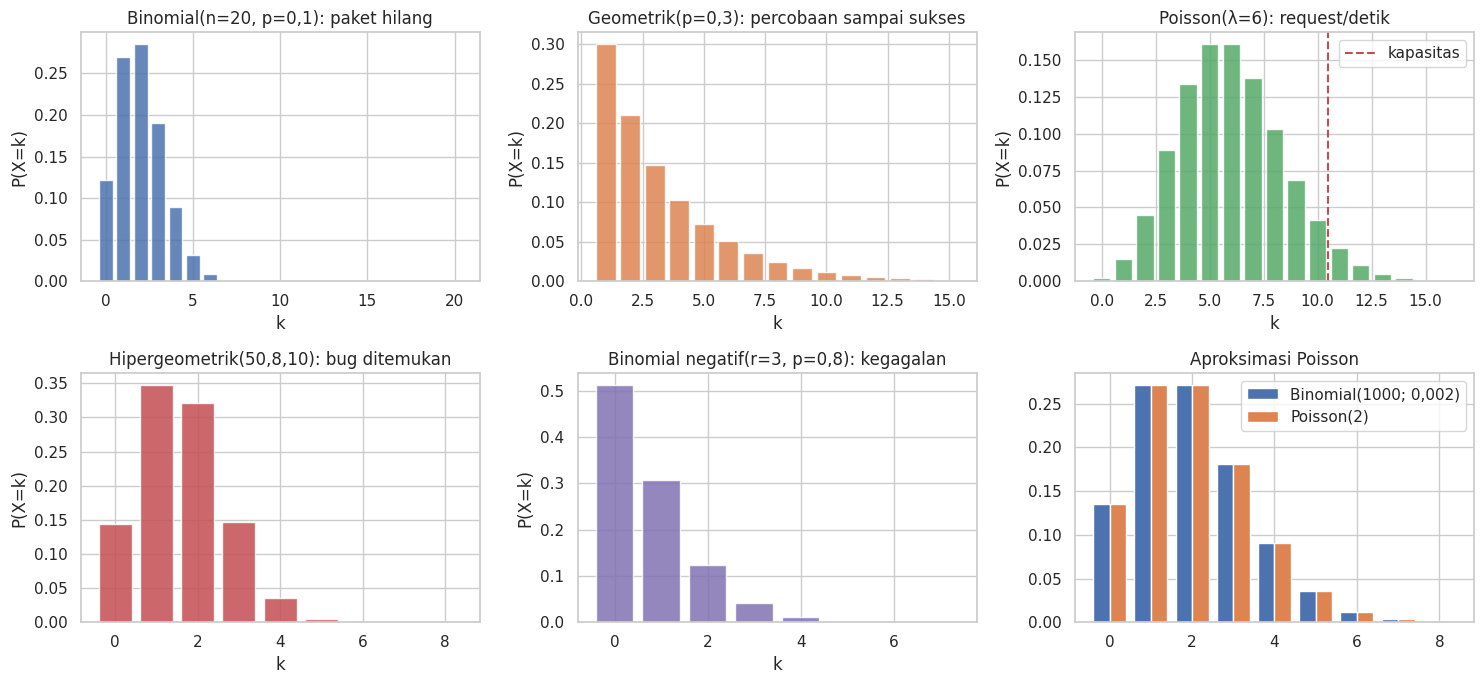

,Distribusi,E[X] teori,E[X] simulasi,Var teori,Var simulasi
0,"Binomial(20;0,1)",2.0000,2.0018,1.8000,1.7964
1,"Geometrik(0,3)",3.3333,3.3342,7.7778,7.7697
2,Poisson(6),6.0000,6.0010,6.0000,5.9950
3,"Hipergeometrik(50,8,10)",1.6000,1.6008,1.0971,1.0951
4,"Binomial negatif(3;0,8)",0.7500,0.7496,0.9375,0.9360


In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
def bar(a, k, pm, judul, warna):
    a.bar(k, pm, color=warna, alpha=.85); a.set_title(judul); a.set_xlabel("k"); a.set_ylabel("P(X=k)")
k = np.arange(0, 21); bar(ax[0, 0], k, stats.binom.pmf(k, 20, .1), "Binomial(n=20, p=0,1): paket hilang", "C0")
k = np.arange(1, 16); bar(ax[0, 1], k, stats.geom.pmf(k, .3), "Geometrik(p=0,3): percobaan sampai sukses", "C1")
k = np.arange(0, 17); bar(ax[0, 2], k, stats.poisson.pmf(k, 6), "Poisson(λ=6): request/detik", "C2")
ax[0, 2].axvline(10.5, color="r", ls="--", label="kapasitas"); ax[0, 2].legend()
k = np.arange(0, 9); bar(ax[1, 0], k, stats.hypergeom.pmf(k, 50, 8, 10), "Hipergeometrik(50,8,10): bug ditemukan", "C3")
k = np.arange(0, 8); bar(ax[1, 1], k, stats.nbinom.pmf(k, 3, .8), "Binomial negatif(r=3, p=0,8): kegagalan", "C4")AS
k = np.arange(0, 9); w = .4
ax[1, 2].bar(k - w/2, stats.binom.pmf(k, 1000, .002), w, label="Binomial(1000; 0,002)")
ax[1, 2].bar(k + w/2, stats.poisson.pmf(k, 2), w, label="Poisson(2)"); ax[1, 2].legend(); ax[1, 2].set_title("Aproksimasi Poisson")
plt.tight_layout(); plt.show()

N = 1_000_000
daftar = {
    "Binomial(20;0,1)": (stats.binom(20, .1), rng.binomial(20, .1, N)),
    "Geometrik(0,3)": (stats.geom(.3), rng.geometric(.3, N)),
    "Poisson(6)": (stats.poisson(6), rng.poisson(6, N)),
    "Hipergeometrik(50,8,10)": (stats.hypergeom(50, 8, 10), rng.hypergeometric(8, 42, 10, N)),
    "Binomial negatif(3;0,8)": (stats.nbinom(3, .8), rng.negative_binomial(3, .8, N)),
}
rekap = pd.DataFrame([[nm, d.mean(), s.mean(), d.var(), s.var()] for nm, (d, s) in daftar.items()],
                     columns=["Distribusi", "E[X] teori", "E[X] simulasi", "Var teori", "Var simulasi"])
rekap.round(4)

## 7. Distribusi Probabilitas Kontinu

### 7.1 Uniform: *random backoff*
**Soal.** Penundaan ulang kirim (*backoff*) berdistribusi $U(0,10)$ ms. Hitung $P(3<X<7)$, $E[X]$, $\mathrm{Var}(X)$.

**Rumus:** $P(3<X<7)=4/10=0{,}4$; $E[X]=5$; $\mathrm{Var}(X)=(b-a)^2/12=8{,}333$.

In [20]:
U = stats.uniform(loc=0, scale=10)
s = rng.uniform(0, 10, 2_000_000)
pr = U.cdf(7) - U.cdf(3)
print("P(3<X<7) = %.4f | E = %.3f | Var = %.4f" % (pr, U.mean(), U.var()))
print("Simulasi : %.4f | mean = %.3f | var = %.4f" % (((s > 3) & (s < 7)).mean(), s.mean(), s.var()))
catat("7 Kontinu", "Uniform(0,10): P(3<X<7)", pr, ((s > 3) & (s < 7)).mean())

P(3<X<7) = 0.4000 | E = 5.000 | Var = 8.3333
Simulasi : 0.4002 | mean = 5.002 | var = 8.3270


### 7.2 Eksponensial dan sifat *memoryless*
**Soal.** Request tiba dengan laju $\lambda=2$ per detik, sehingga selang antar-kedatangan $T\sim\mathrm{Exp}(\lambda=2)$. Hitung $P(T>1)$, $E[T]$, dan buktikan $P(T>3\mid T>2)=P(T>1)$.

**Rumus:** $P(T>t)=e^{-\lambda t}$, jadi $P(T>1)=e^{-2}\approx0{,}1353$, $E[T]=1/\lambda=0{,}5$ s, $\mathrm{Var}=1/\lambda^2=0{,}25$.

In [22]:
lam = 2
E_ = stats.expon(scale=1 / lam)             # scipy memakai scale = 1/lambda
print("P(T>1) = %.5f (e^-2 = %.5f) | E=%.2f Var=%.2f" % (E_.sf(1), math.exp(-2), E_.mean(), E_.var()))
print("P(T>3 | T>2) = sf(3)/sf(2) = %.5f  vs  P(T>1) = %.5f" % (E_.sf(3) / E_.sf(2), E_.sf(1)))
t = rng.exponential(1 / lam, 4_000_000)
cond = (t[t > 2] > 3).mean()
print("Simulasi: P(T>1) = %.5f | P(T>3 | T>2) = %.5f | mean = %.4f" % ((t > 1).mean(), cond, t.mean()))
catat("7 Kontinu", "Eksponensial(2): P(T>1)", E_.sf(1), (t > 1).mean())
catat("7 Kontinu", "Eksponensial(2): P(T>3|T>2) (memoryless)", E_.sf(1), cond)

P(T>1) = 0.13534 (e^-2 = 0.13534) | E=0.50 Var=0.25
P(T>3 | T>2) = sf(3)/sf(2) = 0.13534  vs  P(T>1) = 0.13534
Simulasi: P(T>1) = 0.13534 | P(T>3 | T>2) = 0.13672 | mean = 0.4999


### 7.3 Normal: *response time* dan SLA
**Soal.** Waktu respons API $\sim N(\mu=200,\ \sigma=30)$ ms. Hitung (a) $P(X>250)$, (b) $P(170<X<230)$, (c) persentil ke-95 dan ke-99 (untuk menetapkan target SLA).

**Jawaban matematis:** (a) $z=(250-200)/30=1{,}667$, $P(Z>1{,}667)\approx0{,}0478$; (b) $\pm1\sigma$, sehingga $\approx0{,}6827$; (c) $200+1{,}645\cdot30=249{,}3$ dan $200+2{,}326\cdot30=269{,}8$ ms.

In [21]:
Nrm = stats.norm(200, 30)
a = Nrm.sf(250); b = Nrm.cdf(230) - Nrm.cdf(170)
print("(a) P(X>250) = %.5f (z = %.3f)" % (a, (250 - 200) / 30))
print("(b) P(170<X<230) = %.5f" % b)
print("(c) P95 = %.2f ms | P99 = %.2f ms" % (Nrm.ppf(.95), Nrm.ppf(.99)))
s = rng.normal(200, 30, 4_000_000)
print("Simulasi: (a) %.5f | (b) %.5f | P95 = %.2f | P99 = %.2f" % ((s > 250).mean(), ((s > 170) & (s < 230)).mean(), np.percentile(s, 95), np.percentile(s, 99)))
catat("7 Kontinu", "Normal(200,30): P(X>250)", a, (s > 250).mean())
catat("7 Kontinu", "Normal(200,30): P(170<X<230)", b, ((s > 170) & (s < 230)).mean())

(a) P(X>250) = 0.04779 (z = 1.667)
(b) P(170<X<230) = 0.68269
(c) P95 = 249.35 ms | P99 = 269.79 ms
Simulasi: (a) 0.04780 | (b) 0.68248 | P95 = 249.34 | P99 = 269.80


### 7.4 Gamma/Erlang: tiga tahap layanan berurutan
**Soal.** Sebuah job melewati 3 tahap berurutan, masing-masing berdurasi $\mathrm{Exp}(\lambda=2)$ detik. Total waktu $T$ ~ Gamma$(k=3,\ \theta=0{,}5)$ (Erlang). Hitung $E[T]$, $\mathrm{Var}(T)$, dan $P(T>2)$.

**Rumus:** $E[T]=k\theta=1{,}5$; $\mathrm{Var}(T)=k\theta^2=0{,}75$; $P(T>2)=e^{-4}(1+4+8)=13e^{-4}\approx0{,}2381$ (rumus Erlang).

In [ ]:
Gm = stats.gamma(a=3, scale=0.5)
manual = 13 * math.exp(-4)
print("E = %.3f | Var = %.3f | P(T>2) scipy = %.5f | manual 13e^-4 = %.5f" % (Gm.mean(), Gm.var(), Gm.sf(2), manual))
s = rng.exponential(.5, (2_000_000, 3)).sum(axis=1)           # jumlah 3 eksponensial
print("Simulasi (jumlah 3 eksponensial): P(T>2) = %.5f | mean = %.3f | var = %.3f" % ((s > 2).mean(), s.mean(), s.var()))
catat("7 Kontinu", "Gamma/Erlang(3, 0.5): P(T>2)", manual, (s > 2).mean())

E = 1.500 | Var = 0.750 | P(T>2) scipy = 0.23810 | manual 13e^-4 = 0.23810
Simulasi (jumlah 3 eksponensial): P(T>2) = 0.23752 | mean = 1.499 | var = 0.750


### 7.5 Weibull: umur hard disk
**Soal.** Umur sebuah SSD (tahun) mengikuti Weibull dengan bentuk $c=1{,}5$ dan skala $5$ (laju gagal naik seiring usia). Hitung peluang bertahan lebih dari 3 tahun dan rata-rata umur.

**Rumus:** $P(L>t)=\exp\!\left[-(t/5)^{1{,}5}\right]$, $E[L]=5\,\Gamma(1+1/1{,}5)$.

In [ ]:
Wb = stats.weibull_min(c=1.5, scale=5)
manual_sf = math.exp(-(3 / 5) ** 1.5); manual_mean = 5 * math.gamma(1 + 1 / 1.5)
print("P(L>3) scipy = %.5f | manual = %.5f" % (Wb.sf(3), manual_sf))
print("E[L] scipy = %.4f | manual = %.4f tahun" % (Wb.mean(), manual_mean))
s = 5 * rng.weibull(1.5, 3_000_000)
print("Simulasi: P(L>3) = %.5f | mean = %.4f" % ((s > 3).mean(), s.mean()))
catat("7 Kontinu", "Weibull(1.5, 5): P(L>3)", manual_sf, (s > 3).mean())

P(L>3) scipy = 0.62829 | manual = 0.62829
E[L] scipy = 4.5137 | manual = 4.5137 tahun


Simulasi: P(L>3) = 0.62801 | mean = 4.5140


### 7.6 Beta: pembaruan Bayesian pada A/B testing
**Soal.** Tampilan A: 120 konversi dari 1000 kunjungan. Tampilan B: 145 konversi dari 1000. Dengan prior $\mathrm{Beta}(1,1)$ (seragam), posteriornya $\mathrm{Beta}(1+\text{sukses},\,1+\text{gagal})$. Hitung selang kredibel 95% dan $P(p_B>p_A)$.

**Rumus:** $P(p_B>p_A)=\int_0^1 f_B(x)\,F_A(x)\,dx$. Kita bandingkan integrasi numerik dengan sampling dari posterior.

In [ ]:
postA, postB = stats.beta(1 + 120, 1 + 880), stats.beta(1 + 145, 1 + 855)
print("Posterior A: mean = %.4f, 95%% CI = (%.4f, %.4f)" % (postA.mean(), *postA.interval(.95)))
print("Posterior B: mean = %.4f, 95%% CI = (%.4f, %.4f)" % (postB.mean(), *postB.interval(.95)))
eksak, _ = integrate.quad(lambda x: postB.pdf(x) * postA.cdf(x), 0, 1)
sA, sB = postA.rvs(2_000_000, random_state=1), postB.rvs(2_000_000, random_state=2)
print("P(pB > pA): integrasi numerik = %.5f | sampling = %.5f" % (eksak, (sB > sA).mean()))
catat("7 Kontinu", "A/B Beta: P(pB > pA)", eksak, (sB > sA).mean())

Posterior A: mean = 0.1208, 95% CI = (0.1013, 0.1416)
Posterior B: mean = 0.1457, 95% CI = (0.1246, 0.1682)


P(pB > pA): integrasi numerik = 0.95020 | sampling = 0.95014


**Interpretasi.** Nilai $P(p_B>p_A)$ yang tinggi menunjukkan bukti cukup kuat bahwa B lebih baik, namun selang kredibel keduanya masih beririsan. Inilah keunggulan pendekatan Bayesian: kita memperoleh peluang langsung bahwa "B lebih baik dari A", bukan sekadar menerima/menolak hipotesis.

### 7.7 Teorema Limit Pusat (CLT)
Rata-rata $n$ sampel i.i.d. dari distribusi apa pun (dengan varians hingga) mendekati normal $N(\mu,\sigma^2/n)$. Di sini sumbernya adalah $\mathrm{Exp}(1)$ yang sangat miring ($\mu=\sigma=1$, skewness = 2). Skewness rata-rata $n$ sampel secara teori adalah $2/\sqrt{n}$.

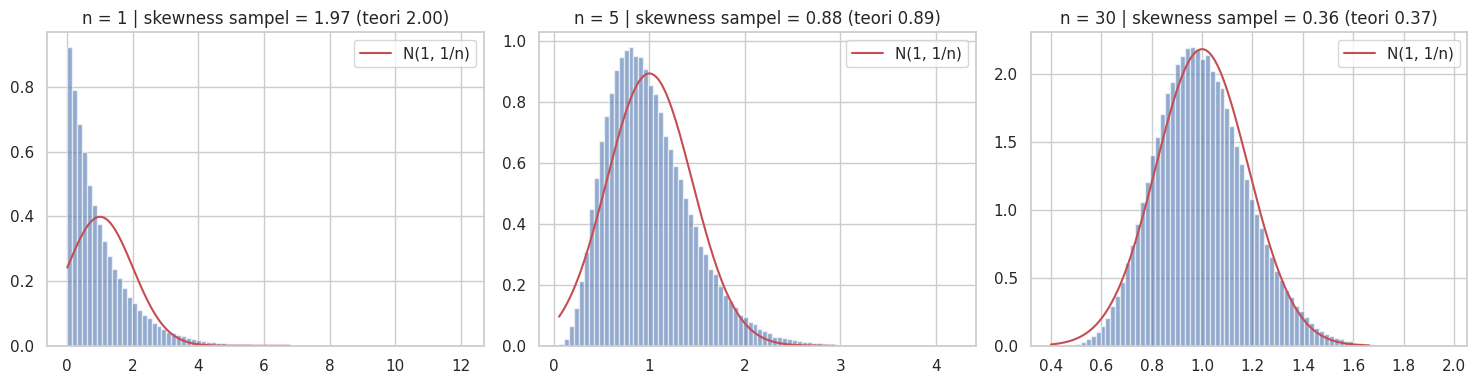

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, n in zip(ax, [1, 5, 30]):
    rata = rng.exponential(1, (200_000, n)).mean(axis=1)
    a.hist(rata, bins=80, density=True, alpha=.6)
    xs = np.linspace(rata.min(), np.percentile(rata, 99.9), 300)
    a.plot(xs, stats.norm.pdf(xs, 1, 1 / math.sqrt(n)), "r", label="N(1, 1/n)")
    a.set_title("n = %d | skewness sampel = %.2f (teori %.2f)" % (n, stats.skew(rata), 2 / math.sqrt(n))); a.legend()
plt.tight_layout(); plt.show()

### 7.8 Visualisasi kumpulan distribusi kontinu

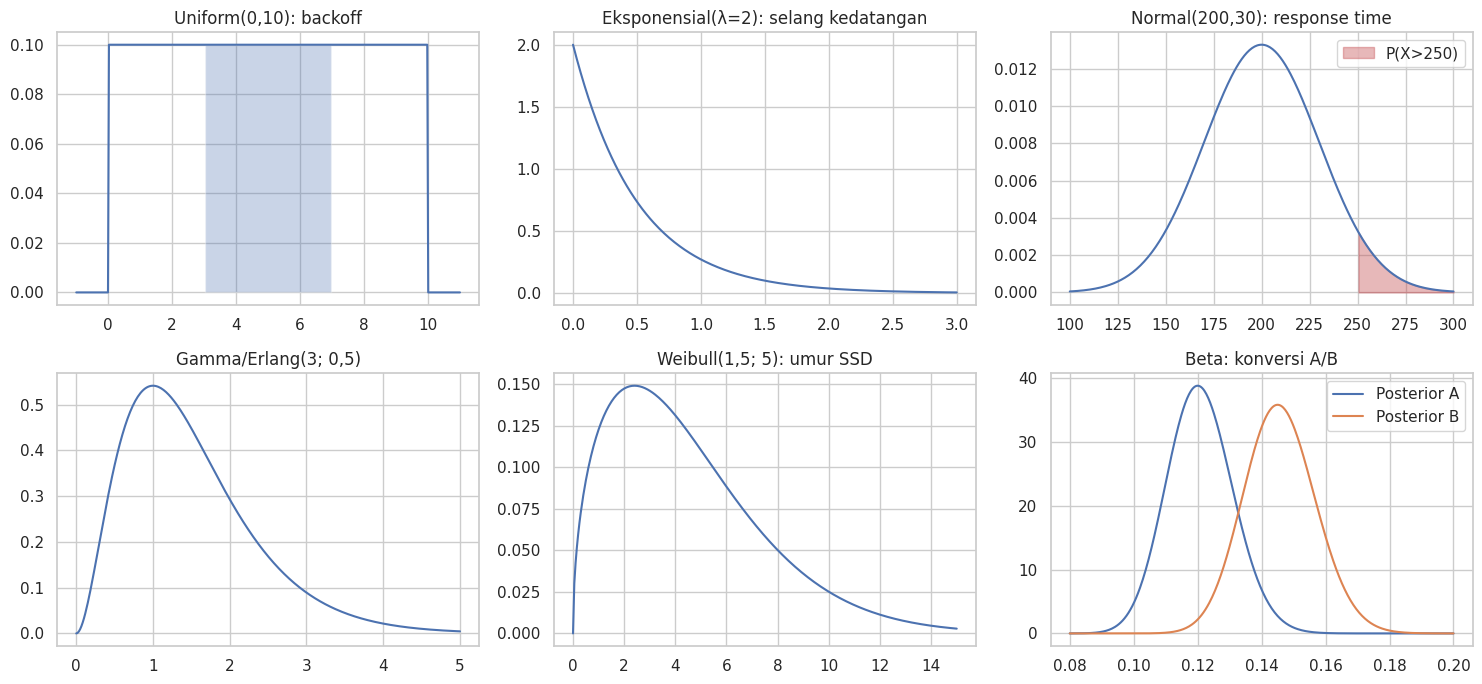

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
x = np.linspace(-1, 11, 400); ax[0, 0].plot(x, stats.uniform(0, 10).pdf(x)); ax[0, 0].set_title("Uniform(0,10): backoff"); ax[0, 0].fill_between(x, stats.uniform(0, 10).pdf(x), where=(x > 3) & (x < 7), alpha=.3)
x = np.linspace(0, 3, 300); ax[0, 1].plot(x, stats.expon(scale=.5).pdf(x)); ax[0, 1].set_title("Eksponensial(λ=2): selang kedatangan")
x = np.linspace(100, 300, 300); ax[0, 2].plot(x, Nrm.pdf(x)); ax[0, 2].fill_between(x, Nrm.pdf(x), where=x > 250, color="r", alpha=.4, label="P(X>250)"); ax[0, 2].set_title("Normal(200,30): response time"); ax[0, 2].legend()
x = np.linspace(0, 5, 300); ax[1, 0].plot(x, Gm.pdf(x)); ax[1, 0].set_title("Gamma/Erlang(3; 0,5)")
x = np.linspace(0, 15, 300); ax[1, 1].plot(x, Wb.pdf(x)); ax[1, 1].set_title("Weibull(1,5; 5): umur SSD")
x = np.linspace(.08, .2, 400); ax[1, 2].plot(x, postA.pdf(x), label="Posterior A"); ax[1, 2].plot(x, postB.pdf(x), label="Posterior B"); ax[1, 2].set_title("Beta: konversi A/B"); ax[1, 2].legend()
plt.tight_layout(); plt.show()

## 8. Studi Kasus Lanjutan

### 8.1 Klasifikasi spam dengan Naive Bayes (dibuat dari nol)
Dengan asumsi kata-kata independen bersyarat pada kelas:
$$P(c\mid d)\propto P(c)\prod_{w\in d}P(w\mid c),\qquad P(w\mid c)=\frac{\text{count}(w,c)+1}{\text{total kata}(c)+|V|}\ \text{(Laplace smoothing)}$$
Perhitungan memakai logaritma agar tidak terjadi *underflow*.

In [23]:
latih = [("gratis hadiah klik sekarang", "spam"), ("menang hadiah gratis undian", "spam"),
         ("klik link gratis pinjaman", "spam"), ("diskon besar klik sekarang", "spam"),
         ("jadwal rapat tugas besok", "ham"), ("kumpul tugas praktikum probabilitas", "ham"),
         ("rapat proyek kelompok besok", "ham"), ("jadwal praktikum minggu depan", "ham"),
         ("tugas proyek dikumpul besok", "ham"), ("hadiah ulang tahun teman", "ham")]

kelas = ["spam", "ham"]
V = sorted({w for teks, _ in latih for w in teks.split()})
jml_dok = Counter(c for _, c in latih)
hitung = {c: Counter(w for teks, cc in latih if cc == c for w in teks.split()) for c in kelas}
total_kata = {c: sum(hitung[c].values()) for c in kelas}

def log_posterior(teks):
    skor = {}
    for c in kelas:
        s = math.log(jml_dok[c] / len(latih))
        for w in teks.split():
            if w in V:                                  # kata di luar kosakata diabaikan
                s += math.log((hitung[c][w] + 1) / (total_kata[c] + len(V)))
        skor[c] = s
    m = max(skor.values()); z = sum(math.exp(v - m) for v in skor.values())
    return {c: math.exp(skor[c] - m) / z for c in kelas}       # normalisasi (log-sum-exp)

uji = [("klik hadiah gratis besok", None), ("gratis klik hadiah undian", "spam"), ("jadwal tugas rapat", "ham"),
       ("klik pinjaman gratis sekarang", "spam"), ("proyek praktikum besok", "ham")]
baris = []
for teks, label in uji:
    pr = log_posterior(teks)
    baris.append([teks, label, max(pr, key=pr.get), round(pr["spam"], 4), round(pr["ham"], 4)])
pd.DataFrame(baris, columns=["Pesan", "Label sebenarnya", "Prediksi", "P(spam|d)", "P(ham|d)"])

,Pesan,Label sebenarnya,Prediksi,P(spam|d),P(ham|d)
0,klik hadiah gratis besok,None,spam,0.8908,0.1092
1,gratis klik hadiah undian,spam,spam,0.9849,0.0151
2,jadwal tugas rapat,ham,ham,0.0306,0.9694
3,klik pinjaman gratis sekarang,spam,spam,0.9924,0.0076
4,proyek praktikum besok,ham,ham,0.0306,0.9694


**Interpretasi.** Pesan pertama ("klik hadiah gratis besok") bersifat ambigu karena memuat kata dari kedua kelas ("besok" lazim di *ham*), dan modelnya menunjukkan peluang masing-masing, bukan sekadar label. Pesan uji lain terklasifikasi sesuai harapan. Ini hanya data mainan (10 dokumen), tetapi mekanismenya sama dengan filter spam sungguhan.

### 8.2 Antrian M/M/1: server tunggal
**Soal.** Request tiba sebagai proses Poisson dengan laju $\lambda=8$/detik dan dilayani satu server dengan waktu layanan $\mathrm{Exp}(\mu=10)$. Dengan utilisasi $\rho=\lambda/\mu=0{,}8$, teori antrian memberi:
- rata-rata waktu menunggu di antrian $W_q=\dfrac{\rho}{\mu-\lambda}=0{,}4$ s,
- rata-rata waktu di sistem $W=\dfrac{1}{\mu-\lambda}=0{,}5$ s,
- waktu di sistem $\sim\mathrm{Exp}(\mu-\lambda)$, sehingga $P(W>1)=e^{-2}\approx0{,}1353$.

Simulasi memakai rekursi Lindley: $W_q^{(n+1)}=\max\!\left(0,\ W_q^{(n)}+S_n-A_{n+1}\right)$.

Wq : teori = 0.4000 | simulasi = 0.4009
W  : teori = 0.5000 | simulasi = 0.5009
P(W>1): teori = 0.1353 | simulasi = 0.1365


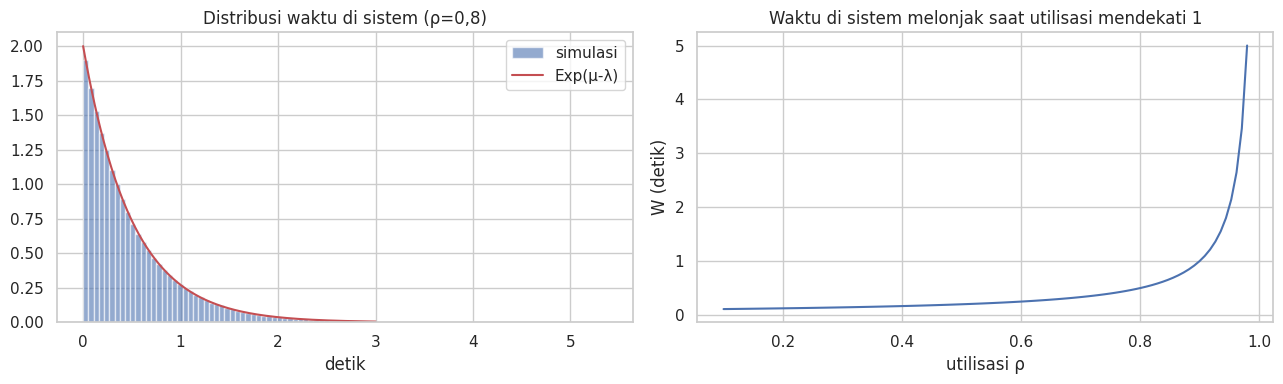

In [24]:
lam, mu, n = 8.0, 10.0, 1_000_000
A = rng.exponential(1 / lam, n)           # selang antar-kedatangan
S = rng.exponential(1 / mu, n)            # waktu layanan
Wq = np.zeros(n)
for i in range(1, n):
    Wq[i] = max(0.0, Wq[i - 1] + S[i - 1] - A[i])
W = Wq + S
buang = 20_000                            # buang fase pemanasan
Wq, W = Wq[buang:], W[buang:]

teori_Wq, teori_W, teori_p = lam / (mu * (mu - lam)), 1 / (mu - lam), math.exp(-(mu - lam) * 1)
print("Wq : teori = %.4f | simulasi = %.4f" % (teori_Wq, Wq.mean()))
print("W  : teori = %.4f | simulasi = %.4f" % (teori_W, W.mean()))
print("P(W>1): teori = %.4f | simulasi = %.4f" % (teori_p, (W > 1).mean()))
catat("8 Lanjutan", "M/M/1: rata-rata waktu di sistem W", teori_W, W.mean())
catat("8 Lanjutan", "M/M/1: P(W>1)", teori_p, (W > 1).mean())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(W, bins=100, density=True, alpha=.6, label="simulasi")
xs = np.linspace(0, 3, 300); ax[0].plot(xs, stats.expon(scale=1 / (mu - lam)).pdf(xs), "r", label="Exp(μ-λ)")
ax[0].set(title="Distribusi waktu di sistem (ρ=0,8)", xlabel="detik"); ax[0].legend()
lams = np.linspace(1, 9.8, 100); ax[1].plot(lams / mu, 1 / (mu - lams))
ax[1].set(title="Waktu di sistem melonjak saat utilisasi mendekati 1", xlabel="utilisasi ρ", ylabel="W (detik)")
plt.tight_layout(); plt.show()

**Interpretasi.** Pada $\rho=0{,}8$ rata-rata waktu di sistem sudah 5 kali waktu layanan murni (0,1 s). Kurvanya melonjak tajam mendekati $\rho=1$. Itulah alasan sistem produksi biasanya dijaga pada utilisasi jauh di bawah 100%.

### 8.3 Rantai Markov: status server
**Soal.** Status server tiap menit: Up, Degraded, atau Down, dengan matriks transisi

| dari \ ke | Up | Degraded | Down |
|---|---|---|---|
| Up | 0,90 | 0,08 | 0,02 |
| Degraded | 0,30 | 0,50 | 0,20 |
| Down | 0,50 | 0,00 | 0,50 |

Tentukan distribusi stasioner $\pi$ (solusi $\pi P=\pi$, $\sum\pi_i=1$), yaitu proporsi waktu jangka panjang di tiap status.

In [25]:
Pm = np.array([[0.90, 0.08, 0.02], [0.30, 0.50, 0.20], [0.50, 0.00, 0.50]])
nama = ["Up", "Degraded", "Down"]

# (1) Eigenvektor kiri dengan eigenvalue 1
w, v = np.linalg.eig(Pm.T)
pi = np.real(v[:, np.argmin(abs(w - 1))]); pi = pi / pi.sum()
# (2) Pangkat matriks P^100 (setiap baris konvergen ke pi)
pi_pow = np.linalg.matrix_power(Pm, 100)[0]
# (3) Simulasi rantai
n = 1_000_000; u = rng.random(n); kum = Pm.cumsum(axis=1)
state = 0; cnt = np.zeros(3)
for i in range(n):
    state = int(np.searchsorted(kum[state], u[i]))
    cnt[state] += 1
sim = cnt / n

print(pd.DataFrame({"Eigenvektor": pi, "P^100": pi_pow, "Simulasi": sim}, index=nama).round(5))
print("Ketersediaan jangka panjang (tidak Down) = %.4f" % (1 - pi[2]))
for j, nm in enumerate(nama):
    catat("8 Lanjutan", "Markov: proporsi waktu status " + nm, pi[j], sim[j])

          Eigenvektor    P^100  Simulasi
Up            0.79114  0.79114   0.79057
Degraded      0.12658  0.12658   0.12663
Down          0.08228  0.08228   0.08280
Ketersediaan jangka panjang (tidak Down) = 0.9177


## 9. Rekapitulasi: Teori/Eksak vs Simulasi Python

In [26]:
df = pd.DataFrame(hasil)
print("Jumlah kasus yang dibandingkan:", len(df))
print("Selisih mutlak terbesar        : %.5f" % df["Selisih mutlak"].max())
print("Rata-rata selisih mutlak       : %.5f" % df["Selisih mutlak"].mean())
df.style.format({"Teori/Eksak": "{:.5f}", "Simulasi": "{:.5f}", "Selisih mutlak": "{:.5f}"}).hide(axis="index")

Jumlah kasus yang dibandingkan: 32
Selisih mutlak terbesar        : 0.00285
Rata-rata selisih mutlak       : 0.00053


Bagian,Kasus,Teori/Eksak,Simulasi,Selisih mutlak
2 Dasar,P(jumlah dua dadu = 7),0.16667,0.16690,0.00023
2 Dasar,P(jumlah dua dadu >= 10),0.16667,0.16654,0.00012
2 Dasar,P(minimal satu 6 dalam 4 lemparan),0.51775,0.51698,0.00077
2 Dasar,P(full house),0.00144,0.00144,0.00000
2 Dasar,Birthday paradox n=23,0.50730,0.50445,0.00285
3 Bayes,Spam: P(spam | kata 'gratis'),0.88889,0.88941,0.00052
3 Bayes,Malware: P(berbahaya | alarm),0.16667,0.16742,0.00075
3 Bayes,Monty Hall: strategi ganti,0.66667,0.66680,0.00013
3 Bayes,Monty Hall: strategi tetap,0.33333,0.33195,0.00138
3 Bayes,Load balancer: P(error),0.02100,0.02101,0.00001


Semua selisih bernilai kecil dan sejalan dengan galat Monte Carlo yang diperkirakan ($\sim 1/\sqrt{n}$). Peristiwa yang sangat jarang (misalnya *full house*, peluang 0,0014) memiliki galat relatif lebih besar daripada galat mutlaknya, sehingga perlu sampel sangat banyak.

## 10. Kesimpulan

1. **Pembagian peran library.** `math`/`itertools`/`fractions` cocok untuk perhitungan eksak dan enumerasi ruang sampel kecil. `numpy` cocok untuk simulasi skala besar. `scipy.stats` menyediakan pmf/pdf, cdf, kuantil, momen, dan sampling untuk puluhan distribusi. `sympy` dipakai untuk menurunkan rumus simbolik. `pandas`, `matplotlib`, dan `seaborn` dipakai untuk menyajikan hasil.
2. **Pendekatan tiga lapis** (rumus manual, perhitungan eksak, simulasi) membantu memverifikasi bahwa soal dan implementasi benar. Semua kasus pada tabel rekapitulasi konsisten.
3. **Hubungan dengan Teknik Informatika.** Birthday paradox (tabrakan hash), Bayes (spam, malware, penelusuran akar masalah), keandalan sistem seri/paralel, Binomial/Poisson/Geometrik (paket, request, retry), Eksponensial/Weibull (selang kedatangan, umur perangkat), Normal (SLA latensi), Beta (A/B testing), Naive Bayes, antrian M/M/1, dan rantai Markov.
4. **Pelajaran konseptual.** *Base rate* menentukan makna sebuah alarm; peluang tabrakan tumbuh kuadratik; waktu tunggu antrian meledak mendekati utilisasi 100%; replikasi meningkatkan keandalan secara nyata; dan CLT menjelaskan mengapa distribusi normal begitu sering muncul pada rata-rata.
5. **Keterbatasan.** Simulasi memberikan hampir-eksak, bukan eksak; kejadian langka memerlukan sampel sangat besar atau teknik khusus (*importance sampling*). Model seperti Naive Bayes dan antrian M/M/1 memuat asumsi (independensi, proses Poisson) yang perlu diuji pada data nyata.